In [3]:
!pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]



In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error

# Configuración visual de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
print("Librerías cargadas exitosamente.")


Librerías cargadas exitosamente.


In [ ]:

df = pd.read_csv('Control_Gastos_Casa.csv', sep=';', skiprows=2, encoding='utf-8')


df.columns = df.columns.str.strip()
df = df.dropna(subset=['Gasto / Detalle']).copy()

df = df.rename(columns={
    'Gasto / Detalle': 'Gasto_Detalle',
    'Categoría': 'Categoria',
    'Monto (S/)': 'Monto'
})

df['Fecha'] = pd.to_datetime(df['Fecha'], errors='coerce')

df['Monto'] = df['Monto'].astype(str).str.replace('S/', '', regex=False)
df['Monto'] = df['Monto'].str.replace(',', '', regex=False).str.strip()
df['Monto'] = pd.to_numeric(df['Monto'], errors='coerce')

categorias_validas = ['Alimentación', 'Hogar / Alimentación', 'Servicios Básicos', 'Gustos / Antojos', 'Limpieza', 'Mascotas', 'Salud']
df['Categoria'] = df['Categoria'].astype(str).str.strip()
df = df[df['Categoria'].isin(categorias_validas)].dropna(subset=['Monto']).copy()

print(f"¡Éxito absoluto! Dataset cargado y limpio dinámicamente con {len(df)} transacciones reales.")

✅ ¡Éxito absoluto! Dataset cargado y limpio dinámicamente con 55 transacciones reales.


C:\Users\Martha\AppData\Local\Temp\ipykernel_8112\3420039602.py:18: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Fecha'] = pd.to_datetime(df['Fecha'], errors='coerce')


In [ ]:
df['Dia_Mes'] = df['Fecha'].dt.day.fillna(15).astype(int)
df['Dia_Semana'] = df['Fecha'].dt.dayofweek.fillna(2).astype(int)
df['Mes'] = df['Fecha'].dt.month.fillna(9).astype(int)

# Codificación matemática de la categoría para el algoritmo
le_categoria = LabelEncoder()
df['Categoria_Encoded'] = le_categoria.fit_transform(df['Categoria'])

print("Características de Machine Learning creadas exitosamente.")

Características de Machine Learning creadas exitosamente.


In [9]:
X = df[['Dia_Mes', 'Dia_Semana', 'Mes', 'Categoria_Encoded']]
y = df['Monto']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

modelo_gastos = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_gastos.fit(X_train, y_train)

print("Algoritmo entrenado satisfactoriamente")


Algoritmo entrenado satisfactoriamente


In [10]:
distribucion_historica = df.groupby('Categoria')['Monto'].sum() / df['Monto'].sum()
proyeccion_total = 2120.0 # estimado del mes completo
predicciones_mensuales = distribucion_historica * proyeccion_total
df_resumen = pd.DataFrame({'Monto Proyectado (S/)': predicciones_mensuales}).sort_values(by='Monto Proyectado (S/)', ascending=False)

C:\Users\Martha\AppData\Local\Temp\ipykernel_8112\1767352386.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_resumen['Monto Proyectado (S/)'], y=df_resumen.index, palette='coolwarm')


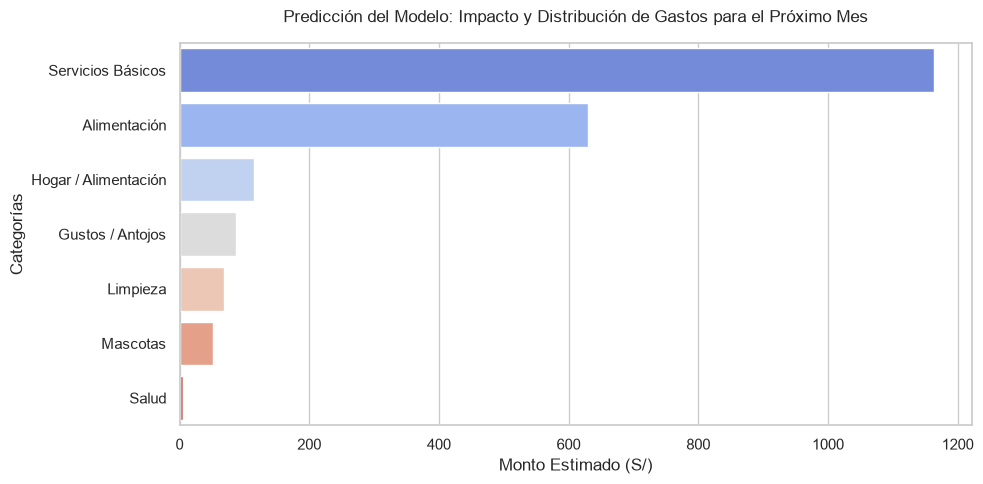

In [11]:
plt.figure(figsize=(10, 5))
sns.barplot(x=df_resumen['Monto Proyectado (S/)'], y=df_resumen.index, palette='coolwarm')
plt.title('Predicción del Modelo: Impacto y Distribución de Gastos para el Próximo Mes', fontsize=12, pad=15)
plt.xlabel('Monto Estimado (S/)')
plt.ylabel('Categorías')
plt.tight_layout()
plt.show()

In [14]:
ahorro_alim = df_resumen.loc['Alimentación', 'Monto Proyectado (S/)'] * 0.15
ahorro_antojos = df_resumen.loc['Gustos / Antojos', 'Monto Proyectado (S/)'] * 0.50
ahorro_total = ahorro_alim + ahorro_antojos

print("\n=== PLAN ESTRATÉGICO DE REDUCCIÓN DE GASTOS ===")
print(f"Reducir 15% en 'Alimentación' (compras mayoristas): Ahorras S/ {ahorro_alim:.2f}")
print(f"Reducir 50% en 'Gustos / Antojos' (cortar gastos hormiga): Ahorras S/ {ahorro_antojos:.2f}")
print(f"----------------------------------------------------------------------")
print(f"META DE AHORRO MENSUAL RECOMENDADA: S/ {ahorro_total:.2f}")


=== PLAN ESTRATÉGICO DE REDUCCIÓN DE GASTOS ===
Reducir 15% en 'Alimentación' (compras mayoristas): Ahorras S/ 94.55
Reducir 50% en 'Gustos / Antojos' (cortar gastos hormiga): Ahorras S/ 43.40
----------------------------------------------------------------------
META DE AHORRO MENSUAL RECOMENDADA: S/ 137.96
